<a href="https://colab.research.google.com/github/GarethH123/Intelligent-Systems-Project/blob/main/CNNFinished.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Install dependencies

In [ ]:
!pip install tensorflow opencv-python matplotlib

In [ ]:
import tensorflow as tf
from tensorflow import keras
from matplotlib import pyplot as plt
%matplotlib inline
import numpy as np
import cv2
import os
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten


2. Load Data

In [ ]:
(X_train, Y_train) , (X_test, Y_test) = keras.datasets.mnist.load_data()




#scale=1./255.
#keras.layers.Rescaling(scale, offset=0.0, X_train)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


and scale the data

In [ ]:

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [ ]:
len(X_train)

60000

In [ ]:
X_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

3. Preprocessing

3.1 Scaling the data Making the numbers in the data as small as possible reduces the computation.

In [ ]:
print(X_train[0])

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.    

4.0 Buidling the model

In [ ]:
model = Sequential()

In [ ]:
#First layer is a convultion, it has 16 layers, kernel is 3 by 3, have a stride of 1
#Output from this convolution is passed through the relu, any output below 0 is converted to 0, preserve any thing above 0
#The max pool takes in the maximum value after the relu function is applied
model.add(Conv2D(16,(3,3),1, activation ='relu', input_shape = (28,28,1)))
model.add(MaxPooling2D())

#Adding double the layers
model.add(Conv2D(32,(3,3),1, activation ='relu'))
model.add(MaxPooling2D())


model.add(Conv2D(16,(3,3),1, activation ='relu'))
model.add(MaxPooling2D())

#Flatten the output to pass through the NN
model.add(Flatten())


#Dense layer is 256 neurons
#Sigmoind takes in the output and makes it result between  0 or 1
model.add(Dense(256, activation ='relu'))
model.add(Dense(10, activation="softmax"))



/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
#Adam is the optimiser, this quantifies how to adjust the functions to reduce the loss function
#(Adaptive Moment Estimation)


# The reason why we have a sparse categorical, is because we have multiple different category outputs from 0 to 9.
# Model.compile(optimizer='adam', loss='mean_squared_error', metrics=['accuracy'])
# Metric your goal is to make it more accurate, so when it predicates you want it to be more accurate.
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
#model.fit(X_train, Y_train, epochs=5)


In [ ]:
model.summary()
# Model shapes the code from 28 by 28 to 26by 26, 16 layers
# Max pooling layer converts it to 13 by 13 with 16 layers
# Next layer is 11 by 11
# Max pool has the image at 5 by 5
# the next layer is 3 by 3
# the max pool of that is 1 by 1 (the max pool halves the output)
# The flatten layer is 1 x 1 x 16 which is passed and flattened to the flatten layer.
# Pass it to the dense layer with 256 neurons
# Then to a single output layer

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 16)       │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,346 (63.85 KB)

 Trainable params: 16,346 (63.85 KB)

 Non-trainable params: 0 (0.00 B)

4.2 Training

In [ ]:
logdir='logs'

In [ ]:
#this will monitor the learning rate

tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=logdir)

In [ ]:
#epoch how many full run throughs
#Valdiations data
#tensor call back
#History = hist
#hist = model.fit(X_train, Y_train, epochs=20, validation_data=(X_test, Y_test), callbacks=[tensorboard_callback])
hist = model.fit(X_train, Y_train, epochs=5, validation_data=(X_test, Y_test), callbacks=[tensorboard_callback])

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 44s 22ms/step - accuracy: 0.9119 - loss: 0.2812 - val_accuracy: 0.9674 - val_loss: 0.1106
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.9681 - loss: 0.1038 - val_accuracy: 0.9780 - val_loss: 0.0737
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 33s 18ms/step - accuracy: 0.9753 - loss: 0.0796 - val_accuracy: 0.9767 - val_loss: 0.0760
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 43s 19ms/step - accuracy: 0.9794 - loss: 0.0652 - val_accuracy: 0.9808 - val_loss: 0.0601
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.9818 - loss: 0.0566 - val_accuracy: 0.9841 - val_loss: 0.0542


4.3 Find the best model

In [ ]:
keras.callbacks.ModelCheckpoint(
    filepath='best_model.keras',
    monitor="val_loss",
    verbose=0,
    save_best_only=True,
    save_weights_only=False,
    mode="auto",
    save_freq="epoch",
    initial_value_threshold=None,
)

4.4 Plot performance

In [ ]:
hist.history

{'accuracy': [0.9119499921798706,
  0.9680500030517578,
  0.9753000140190125,
  0.9794166684150696,
  0.9818000197410583],
 'loss': [0.28122958540916443,
  0.10378912091255188,
  0.07964632660150528,
  0.06524423509836197,
  0.05658913403749466],
 'val_accuracy': [0.9674000144004822,
  0.9779999852180481,
  0.9767000079154968,
  0.9807999730110168,
  0.9840999841690063],
 'val_loss': [0.11057914793491364,
  0.07374419271945953,
  0.07599136978387833,
  0.060135893523693085,
  0.05421490967273712]}

Visualisation for Loss

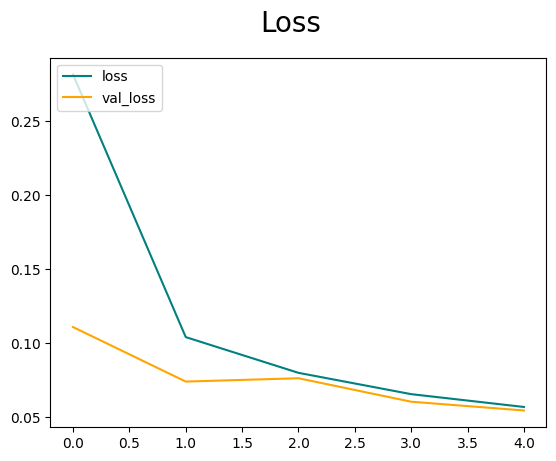

In [ ]:
fig = plt.figure()
plt.plot(hist.history['loss'], color='teal', label='loss')
plt.plot(hist.history['val_loss'], color='orange', label='val_loss')
fig.suptitle('Loss', fontsize=20)
plt.legend(loc="upper left")
plt.show()

Visulisation for accuracy

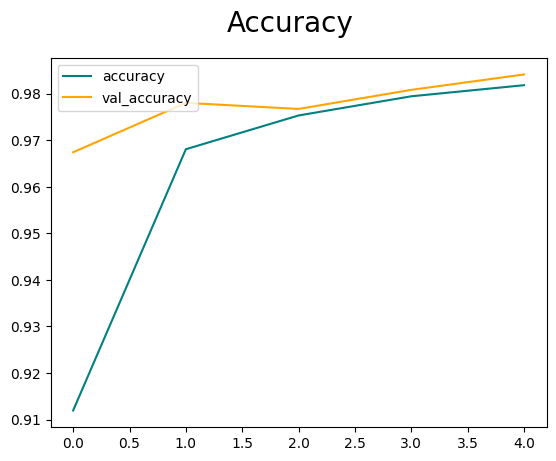

In [ ]:
fig = plt.figure()
plt.plot(hist.history['accuracy'], color='teal', label='accuracy')
plt.plot(hist.history['val_accuracy'], color='orange', label='val_accuracy')
fig.suptitle('Accuracy', fontsize=20)
plt.legend(loc="upper left")
plt.show()

5.0 Evaluate

5.1 Confusion matrix

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


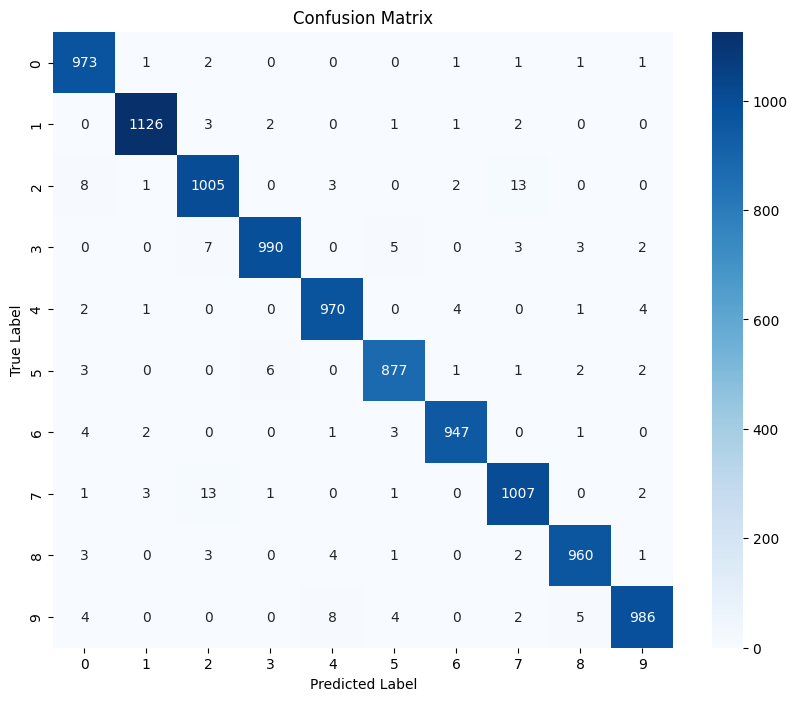

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Get predictions for the test dataset
y_pred= model.predict(X_test)
y_pred_labels = np.argmax(y_pred, axis=1)

# 2. Compute the confusion matrix
cm = confusion_matrix(Y_test, y_pred_labels)

# 3. Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

5.2 Classification report

In [ ]:
from sklearn.metrics import classification_report

# Generate the classification report
report = classification_report(Y_test, y_pred_labels)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.97      0.97      1032
           3       0.99      0.98      0.99      1010
           4       0.98      0.99      0.99       982
           5       0.98      0.98      0.98       892
           6       0.99      0.99      0.99       958
           7       0.98      0.98      0.98      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



6.1 test

In [ ]:
y_predicted = model.predict(X_test)
y_predicted[1]

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


array([4.0578566e-04, 5.0956533e-07, 9.9958736e-01, 8.4859799e-08,
       1.2828443e-06, 4.0721239e-11, 2.8335898e-09, 6.5906349e-08,
       4.6148211e-06, 2.9151244e-07], dtype=float32)

In [ ]:
#Compare the values.
#For each of the values test if the value is the same, if not.
#Pick the best check point from the epoch set pick the model with the lowest loss and highest accuracy.

In [ ]:
np.argmax(y_predicted[1])

np.int64(2)

In [ ]:
Y_test[1]

np.uint8(2)